# Exploring one test

A starting point for the project: it opens one test, shows what the file holds, and draws the
views you will keep coming back to. Copy it, change it, break it.

**Before running it**

1. The data file `ARC-00_m45_s2.h5` is in `data/`, or the environment variable `ONSETML_DATA`
   points to its folder.
2. The package is installed: `pip install -e ".[dev]"` from the root of the repository.

What the variables mean, the frame and the units: [`docs/data.md`](../docs/data.md). Read it
alongside.

**The setting in one paragraph.** A composite coupon with two notches is loaded until it breaks.
Two cameras film one face of it, and a digital image correlation (DIC) turns the images into a
displacement on a triangular mesh, then into a strain per triangle (an *element*). At low load
the strain grows in proportion to the load. Somewhere, at some load, it stops doing so: the
material starts to yield or to crack. The project is about finding **where and when** that
happens, from the strain alone.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from onsetml import data, plotting

plt.rcParams.update({"figure.dpi": 90, "axes.grid": False})

TEST = "ARC-00_m45_s2"  # any file in data/: ARC-00_s0, ARC-00_45_s0, ARC-00_m90_s0, ...
ds = data.load(TEST)

# a few attributes are stored as JSON text
peak = int(ds.attrs["peak_image"])
static = np.array(json.loads(ds.attrs["static_images"]))
roots = np.array(json.loads(ds.attrs["notch_roots_x1_x3_mm"]))  # (2, 2): x1, x3 of each root

images = data.loading_images(ds)  # reference, static, unusable and post-peak images left out
img = ds["image"].values  # image numbers (on ARC-00_s0 only every 5th image)
F = np.full(img.max() + 1, np.nan)  # load over the peak load, indexed by image number
F[img] = ds["load_over_max"].values
blurred = img[ds["mask_blurred"].values]

# light events: the brightness gain of the cameras (mean of the two) more than 1.5 percent away
# from its running median over 41 images
gain = ds["grey_correction"].sel(grey_parameter=["a_0", "a_1"]).values.mean(axis=1)
light = img[np.abs(gain - pd.Series(gain).rolling(41, center=True, min_periods=1).median()) > 0.015]


def mark(ax, which, color, label=None):
    # shade the given images (numbers) on an axis whose x is the image number
    for k, i in enumerate(which):
        ax.axvspan(i - 0.5, i + 0.5, color=color, alpha=0.25, lw=0, label=label if k == 0 else None)


print(
    f"{TEST}: {ds.sizes['image']} images, {ds.sizes['element']} elements, {ds.sizes['node']} nodes"
)
print(
    f"peak {ds.attrs['peak_load_kN']:.3f} kN at image {peak}; {static.size} static images "
    f"({static.min()} to {static.max()}); {images.size} loading images"
)
print(f"blurred frames: {blurred.tolist()}; light events: {light.tolist()}")
ds

ARC-00_m45_s2: 326 images, 7377 elements, 3891 nodes
peak 2.098 kN at image 324; 40 static images (1 to 40); 283 loading images
blurred frames: [128]; light events: [127, 128, 129, 130, 131, 132, 133, 134, 135]


<xarray.Dataset> Size: 83MB
Dimensions:              (image: 326, node: 3891, direction: 3, rigid_mode: 6,
                          element: 7377, component: 3, camera: 2, corner: 3,
                          grey_parameter: 4)
Coordinates:
  * image                (image) int64 3kB 0 1 2 3 4 5 ... 321 322 323 324 325
  * direction            (direction) <U2 24B 'u1' 'u3' 'w'
  * rigid_mode           (rigid_mode) <U12 288B 't1_mm' 't3_mm' ... 'tilt3_rad'
  * component            (component) <U3 36B 'e11' 'e33' 'g13'
  * camera               (camera) <U7 56B 'camera0' 'camera1'
  * grey_parameter       (grey_parameter) <U3 48B 'a_0' 'b_0' 'a_1' 'b_1'
Dimensions without coordinates: node, element, corner
Data variables: (12/30)
    displacement         (image, node, direction) float32 15MB ...
    rigid_motion         (image, rigid_mode) float64 16kB ...
    strain               (image, element, component) float32 29MB ...
    residual_rms         (image, camera, element) float32 19MB ...
    node_x1              (node) float64 31kB ...
    node_x3              (node) float64 31kB ...
    ...                   ...
    mask_not_converged   (image) bool 326B False False False ... False False
    mask_after_peak      (image) bool 326B False False False ... False True
    mask_blurred         (image) bool 326B False False False ... False False
    mask_no_pixel        (element) bool 7kB ...
    residual_over_floor  (image, element) float32 10MB ...
    residual_frac3       (image, element) float32 10MB ...
Attributes: (12/43)
    title:                        global DIC of one test (onsetgp, step K94):...
    test_id:                      ARC-00_m45_s2
    source_run:                   gdic/stereo_T3_graded_0p25_to_0p60mm.nc
    stage:                        stereo
    mesh:                         T3_graded_0p25_to_0p60mm
    kind:                         T3
    ...                           ...
    residual_still_images:        [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...
    config_hash:                  e9553258e087
    git_sha:                      166bbc11b6b097bbfcf5d9e3406c3b75a095709e
    git_dirty:                    true
    created:                      2026-11-07T22:53:19+00:00
    _json_attrs:                  ["grey_correction", "static_images", "notch...

How the field was measured: the settings of the DIC solver, stored in the file as JSON. What
the ones that matter mean is in [`docs/data.md`](../docs/data.md#how-the-field-was-measured).

In [2]:
json.loads(ds.attrs["gdic_settings"])

{'meshes': ['T3_graded_0p25_to_0p60mm', 'T6_graded_0p50_to_1p20mm'],
 'stages': ['2d', 'stereo'],
 'regulariser': 'second_gradient',
 'l_reg_mm': 1.0,
 'tol_du_px': 0.001,
 'tol_r': 1e-05,
 'n_iter_max': 50,
 'grey_correction': True,
 'criterion': 'ssd',
 'epipolar_shift': True,
 'grey_min_points': 12,
 'grey_min_sd': 3.0,
 'image_step': 1,
 'blur_drop': 0.05,
 'blur_window': 9,
 'last_image': 325,
 'start_line': True,
 'refactor_cg': 10,
 'backend': 'cpu',
 'n_workers': 0,
 'map_images': [65, 130, 194, 259, 324],
 'sweep_l_reg_mm': [0.25, 0.5, 1.0, 2.0, 4.0],
 'sweep_images': [20, 324]}

## 1. The load history

One image pair every 0.5 s (on ARC-00_s0 only every 5th image was correlated). The machine
stands still for the first images (the *static* images: use them to measure the noise), then
pulls until the coupon breaks.

Two things are not the material and are marked here:

- **Light events.** The lower panel shows the brightness correction fitted per camera. When the
  light changes (on ARC-00_m45_s2 it dips by about 5 percent over images 127 to 135), the DIC
  corrects for it, but keep those images in mind: a jump that every element shows at the same
  image is more likely the light than the material.
- **Blurred frames**, where a camera moved during the exposure. They are flagged
  (`mask_blurred`) and `data.loading_images` leaves them out.

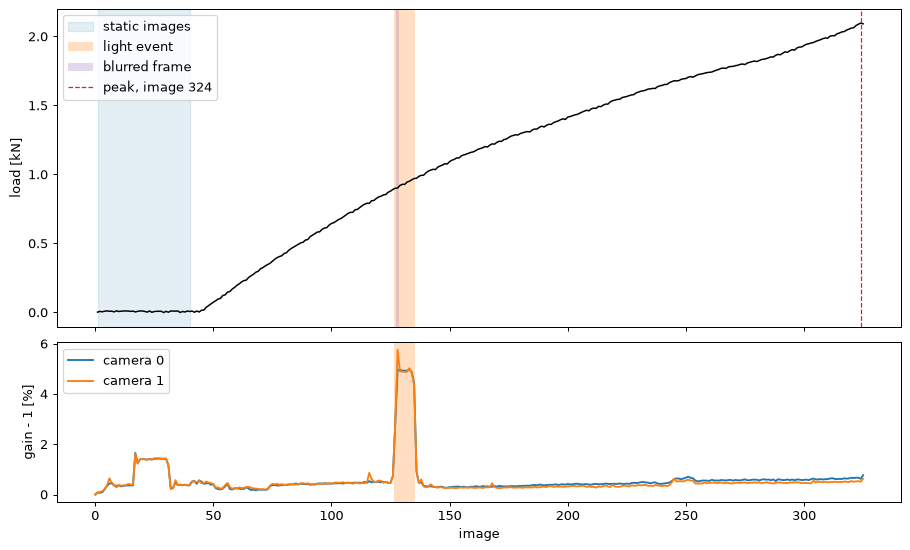

mask_reference         1
mask_static           40
mask_not_converged     0
mask_blurred           1
mask_after_peak        1
Name: images, dtype: int64

In [3]:
fig, (ax, bx) = plt.subplots(
    2, 1, figsize=(10, 6), sharex=True, height_ratios=(2, 1), constrained_layout=True
)
ax.plot(img, ds["load_kN"], color="k", lw=1.2)
ax.axvspan(static.min(), static.max(), color="tab:blue", alpha=0.12, label="static images")
mark(ax, light, "tab:orange", "light event")
mark(ax, blurred, "tab:purple", "blurred frame")
ax.axvline(peak, color="tab:red", lw=1, ls="--", label=f"peak, image {peak}")
ax.set_ylabel("load [kN]")
ax.legend(loc="upper left")

a = ds["grey_correction"].sel(grey_parameter=["a_0", "a_1"]).values
bx.plot(img, a[:, 0] * 100, label="camera 0")
bx.plot(img, a[:, 1] * 100, label="camera 1")
mark(bx, light, "tab:orange")
bx.set_ylabel("gain - 1 [%]")
bx.set_xlabel("image")
bx.legend(loc="upper left")
plt.show()

pd.Series(
    {
        m: int(ds[m].sum())
        for m in [
            "mask_reference",
            "mask_static",
            "mask_not_converged",
            "mask_blurred",
            "mask_after_peak",
        ]
    },
    name="images",
)

## 2. The mesh

The face is the plane `x1`, `x3` (mm). The two notches cut into it from opposite edges; the
region between their roots is the *ligament*, where the coupon will break. The mesh is finer near
the notches (about 0.25 mm) than far from them (about 0.6 mm), so one element does not stand for
the same area everywhere.

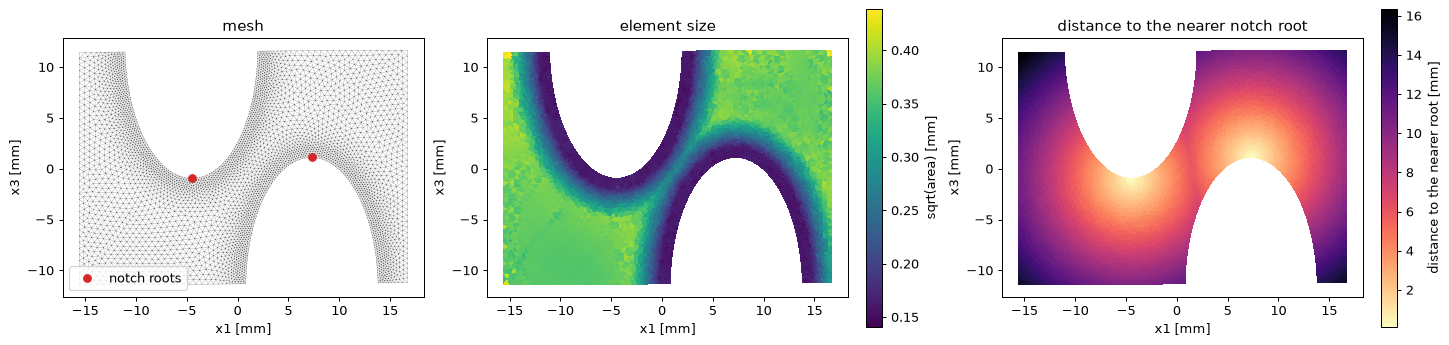

In [4]:
tri = plotting.triangulation(ds)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)

axes[0].triplot(tri, lw=0.2, color="0.4")
axes[0].plot(*roots.T, "o", color="tab:red", ms=6, label="notch roots")
axes[0].set_title("mesh")
axes[0].legend(loc="lower left")

size = np.sqrt(ds["element_area_mm2"].values)
plotting.element_map(ds, size, ax=axes[1], label="sqrt(area) [mm]", cmap="viridis")
axes[1].set_title("element size")

plotting.element_map(
    ds,
    ds["element_root_mm"].values,
    ax=axes[2],
    label="distance to the nearer root [mm]",
    cmap="magma_r",
)
axes[2].set_title("distance to the nearer notch root")
for a in axes:
    a.set_aspect("equal")
    a.set_xlabel("x1 [mm]")
    a.set_ylabel("x3 [mm]")
plt.show()

## 3. Strain fields along the loading

The three components at four load levels. Colour limits are fixed per component, from the
field at the peak, so the panels of a row compare directly. `g13` is the engineering shear.

The maps are averaged at the nodes (`plotting.element_map(..., nodal=True)`), the smooth picture
FE and DIC software show by default. The file itself holds one strain per triangle: the panel
after these maps shows what the averaging does to it.

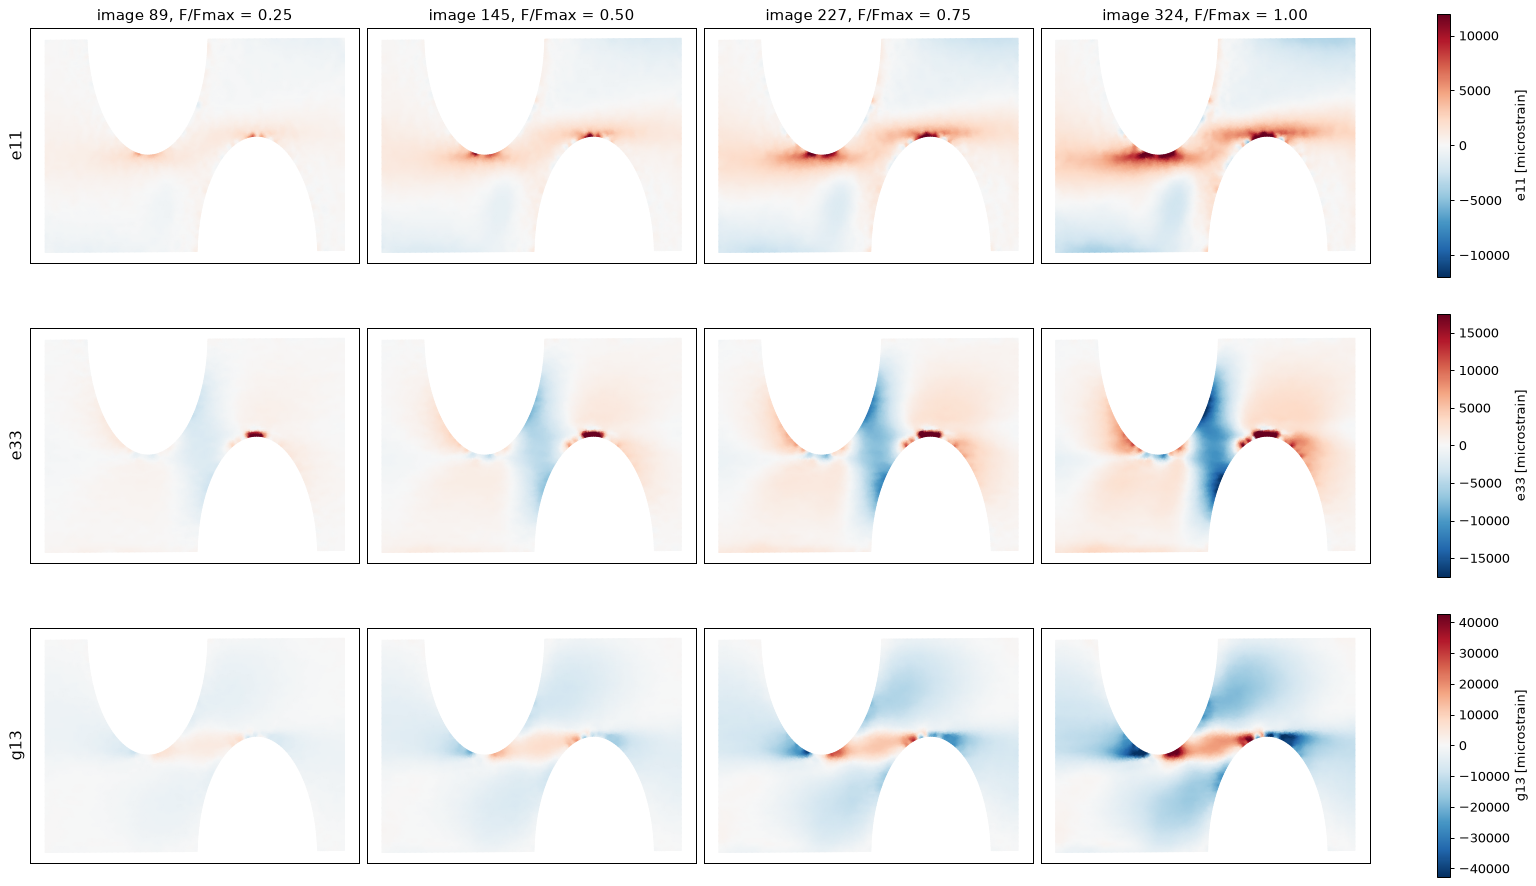

In [5]:
levels = [0.25, 0.5, 0.75, 1.0]
picks = [int(images[np.argmax(F[images] >= q - 1e-9)]) for q in levels]
at_peak = data.field(ds, peak)

fig, axes = plt.subplots(3, 4, figsize=(17, 10), constrained_layout=True)
for c, name in enumerate(data.COMPONENTS):
    lim = np.nanpercentile(np.abs(at_peak[:, c]), 99) * 1e6
    for j, im in enumerate(picks):
        ax = axes[c, j]
        plotting.element_map(
            ds,
            data.field(ds, im)[:, c] * 1e6,
            ax=ax,
            nodal=True,
            colorbar=False,
            cmap="RdBu_r",
            vmin=-lim,
            vmax=lim,
        )
        pc = ax.collections[-1]
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.set_xticks([])
        ax.set_yticks([])
        if c == 0:
            ax.set_title(f"image {im}, F/Fmax = {F[im]:.2f}")  # F is indexed by image number
    axes[c, 0].set_ylabel(name, fontsize=13)
    fig.colorbar(pc, ax=axes[c, :], shrink=0.9, label=f"{name} [microstrain]")
plt.show()

**Per element or averaged at the nodes?** Both views of `e33` at the peak, on the whole face and
around the root of the lower notch (the one whose tip points up). Each node takes the mean of the
triangles around it, weighted by area, so the averaged map is smoother: it looks less noisy than
the data are (the numbers below the figure say by how much), and it spreads the sharp change at
the notch root over a few elements. Use the averaged maps to look at the field, and the element
values (what the file holds, and what the rest of this notebook computes on) for any number.

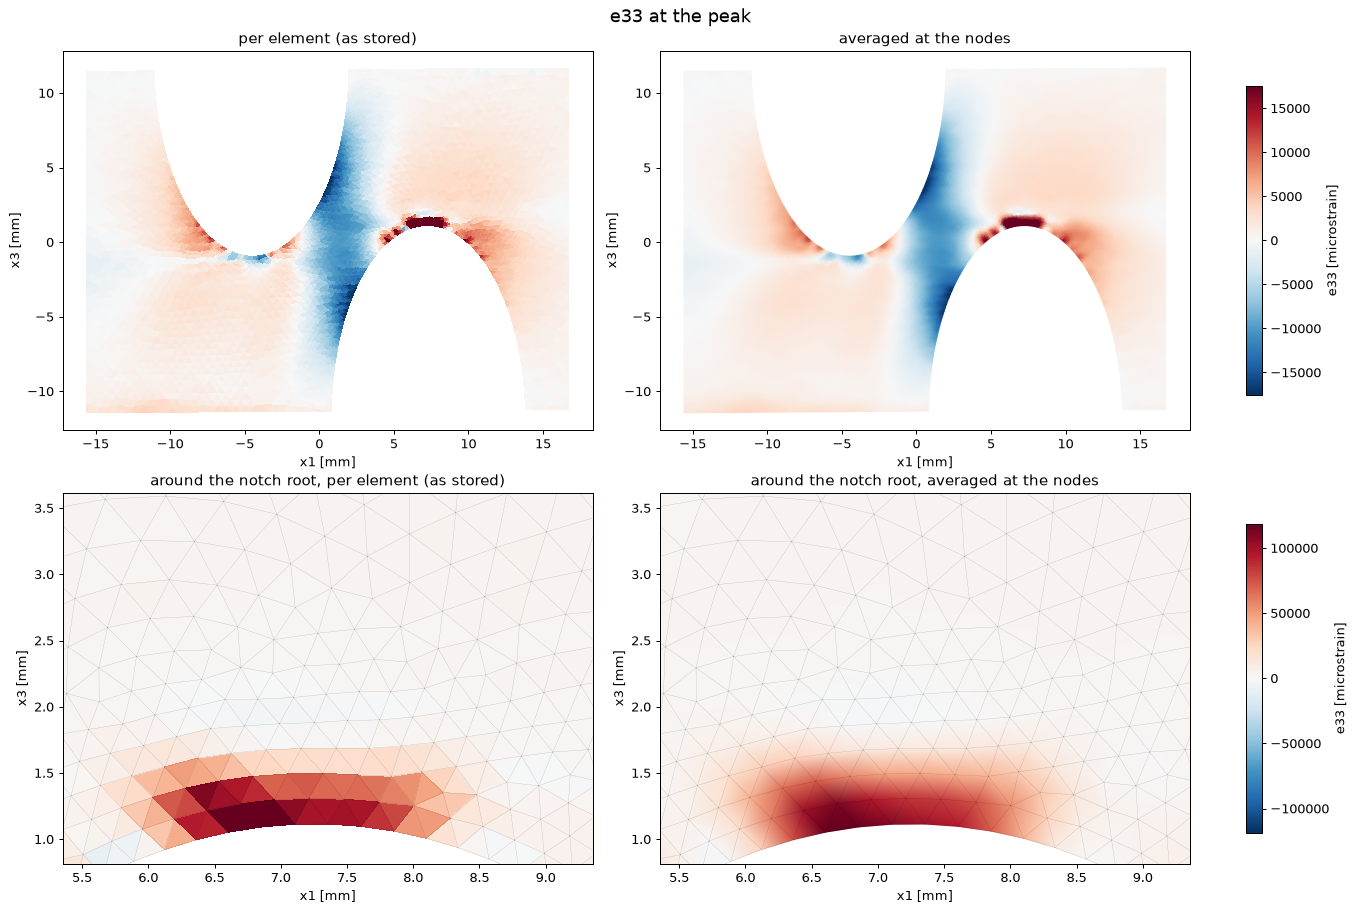

noise at rest of e33 (median sd over the elements more than 0.5 mm inside the outline): 74 microstrain per element, 33 after averaging at the nodes


In [6]:
c = data.COMPONENTS.index("e33")
v = at_peak[:, c] * 1e6
root = roots[np.argmax(roots[:, 1])]  # the root of the lower notch, the higher of the two
box = (root[0] - 2, root[0] + 2, root[1] - 0.3, root[1] + 2.5)
x1, x3 = ds["element_x1"].values, ds["element_x3"].values
inbox = (x1 > box[0]) & (x1 < box[1]) & (x3 > box[2]) & (x3 < box[3])
fig, axes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)
for i in range(2):
    lim = np.nanpercentile(np.abs(v[inbox] if i else v), 99)
    for j, (avg, title) in enumerate(
        [(False, "per element (as stored)"), (True, "averaged at the nodes")]
    ):
        ax = axes[i, j]
        plotting.element_map(
            ds, v, ax=ax, nodal=avg, colorbar=False, cmap="RdBu_r", vmin=-lim, vmax=lim
        )
        if i == 1:
            ax.triplot(tri, color="k", lw=0.2, alpha=0.3)
            ax.set_xlim(box[0], box[1])
            ax.set_ylim(box[2], box[3])
        ax.set_title(("around the notch root, " if i else "") + title)
    fig.colorbar(axes[i, 1].collections[0], ax=axes[i, :], shrink=0.8, label="e33 [microstrain]")
fig.suptitle("e33 at the peak", fontsize=14)
plt.show()

# the noise at rest, per element and after averaging at the nodes (then back to each element as
# the mean of its three nodes, so the two compare element by element)
keep = ds["mask_static"].values & ~ds["mask_reference"].values & data.usable(ds)
rest = ds["strain"].sel(image=img[keep], component="e33").values.T * 1e6  # (n_element, n_static)
back = plotting.nodal_average(ds, rest)[ds["elements"].values].mean(axis=1)
inner = ds["element_edge_mm"].values > 0.5
print(
    f"noise at rest of e33 (median sd over the elements more than 0.5 mm inside the outline): "
    f"{np.nanmedian(rest[inner].std(axis=1, ddof=1)):.0f} microstrain per element, "
    f"{np.nanmedian(back[inner].std(axis=1, ddof=1)):.0f} after averaging at the nodes"
)

## 4. The noise at rest

Over the static images nothing moves, so whatever the strain does there is noise. Its standard
deviation per element is the natural yardstick: a change of 3 to 5 times it is worth looking at,
less is not.

The noise is not uniform. Elements within about 0.5 mm of the outline of the face are much
noisier (part of what they see is not the face): leave them out, or treat them apart. The bright
band along the notches, which carries no speckle, is smoothed by the DIC: low noise there does
not mean a good measurement.

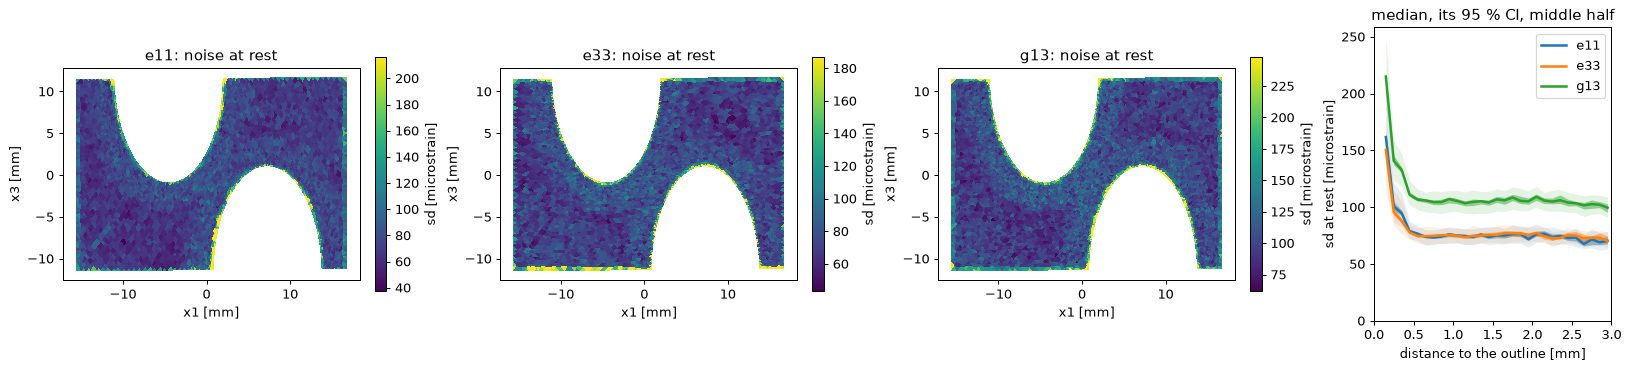

,e11,e33,g13
p10,61.0,62.0,87.0
median,76.0,76.0,107.0
p90,112.0,102.0,151.0


In [7]:
sd = data.static_noise(ds)  # (n_element, 3)
fig, axes = plt.subplots(
    1, 4, figsize=(18, 4), constrained_layout=True, width_ratios=(1, 1, 1, 0.8)
)
for c, name in enumerate(data.COMPONENTS):
    plotting.element_map(
        ds,
        sd[:, c] * 1e6,
        ax=axes[c],
        label="sd [microstrain]",
        cmap="viridis",
        vmax=np.nanpercentile(sd[:, c], 98) * 1e6,
    )
    axes[c].set_title(f"{name}: noise at rest")
# the noise against the distance to the outline, in bins of 0.1 mm: the median over the
# elements of the bin, the 95 % confidence interval of that median (dark band, from the order
# statistics), and the middle half of the elements (light band)
edge = ds["element_edge_mm"].values
bins = np.arange(0, 3.05, 0.1)
mid = (bins[:-1] + bins[1:]) / 2
which = np.digitize(edge, bins) - 1
for c, name in enumerate(data.COMPONENTS):
    q = np.full((len(mid), 5), np.nan)  # median, ci low, ci high, 25 %, 75 %
    for b in range(len(mid)):
        v = np.sort(sd[which == b, c] * 1e6)
        n = v.size
        if n < 10:
            continue
        half = 1.96 * np.sqrt(n) / 2
        lo, hi = int(np.floor(n / 2 - half)), int(np.ceil(n / 2 + half))
        q[b] = np.median(v), v[max(lo, 0)], v[min(hi, n - 1)], *np.percentile(v, [25, 75])
    (line,) = axes[3].plot(mid, q[:, 0], "-", lw=2, label=name)
    axes[3].fill_between(mid, q[:, 1], q[:, 2], color=line.get_color(), alpha=0.45, lw=0)
    axes[3].fill_between(mid, q[:, 3], q[:, 4], color=line.get_color(), alpha=0.12, lw=0)
axes[3].set_xlim(0, 3)
axes[3].set_ylim(bottom=0)
axes[3].set_xlabel("distance to the outline [mm]")
axes[3].set_ylabel("sd at rest [microstrain]")
axes[3].set_title("median, its 95 % CI, middle half")
axes[3].legend()
plt.show()

pd.DataFrame(
    np.nanpercentile(sd, [10, 50, 90], axis=0) * 1e6,
    index=["p10", "median", "p90"],
    columns=data.COMPONENTS,
).round(0)

The same maps with the elements within 0.5 mm of the outline left out, and the colour scale set
on the rest: what remains is the noise of the face itself.

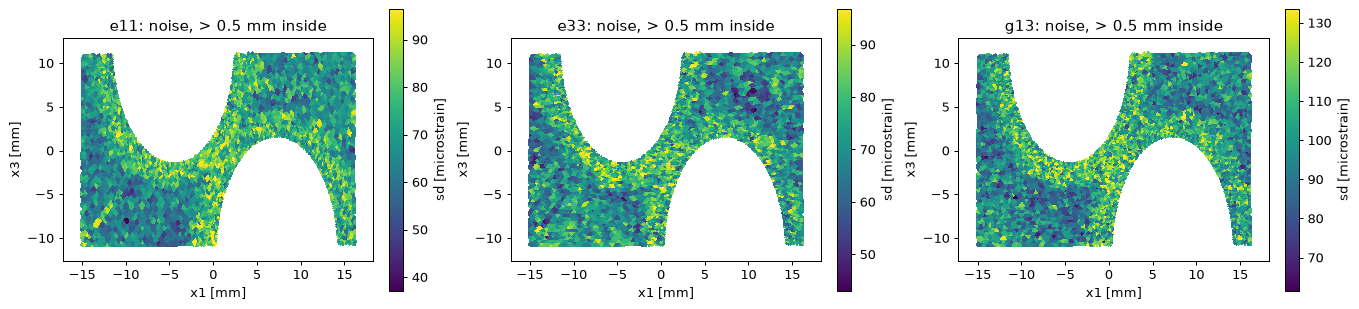

,e11,e33,g13
p10,59.0,61.0,86.0
median,73.0,74.0,103.0
p90,87.0,87.0,122.0


In [8]:
inside = ds["element_edge_mm"].values > 0.5
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for c, name in enumerate(data.COMPONENTS):
    v = np.where(inside, sd[:, c], np.nan) * 1e6
    plotting.element_map(
        ds, v, ax=axes[c], label="sd [microstrain]", cmap="viridis", vmax=np.nanpercentile(v, 98)
    )
    axes[c].set_title(f"{name}: noise, > 0.5 mm inside")
plt.show()

pd.DataFrame(
    np.nanpercentile(sd[inside], [10, 50, 90], axis=0) * 1e6,
    index=["p10", "median", "p90"],
    columns=data.COMPONENTS,
).round(0)

## 5. A few element histories

The strain of one element against the load. Where the curve is straight, the material responds
elastically; where it bends, something else is going on. The grey band is plus or minus 3
standard deviations of that element's noise at rest, drawn around a straight line fitted at low
load (here up to 30 percent of the peak), to show what bending is larger than noise.

Change `chosen` to look elsewhere: the map on the left shows where the elements are.

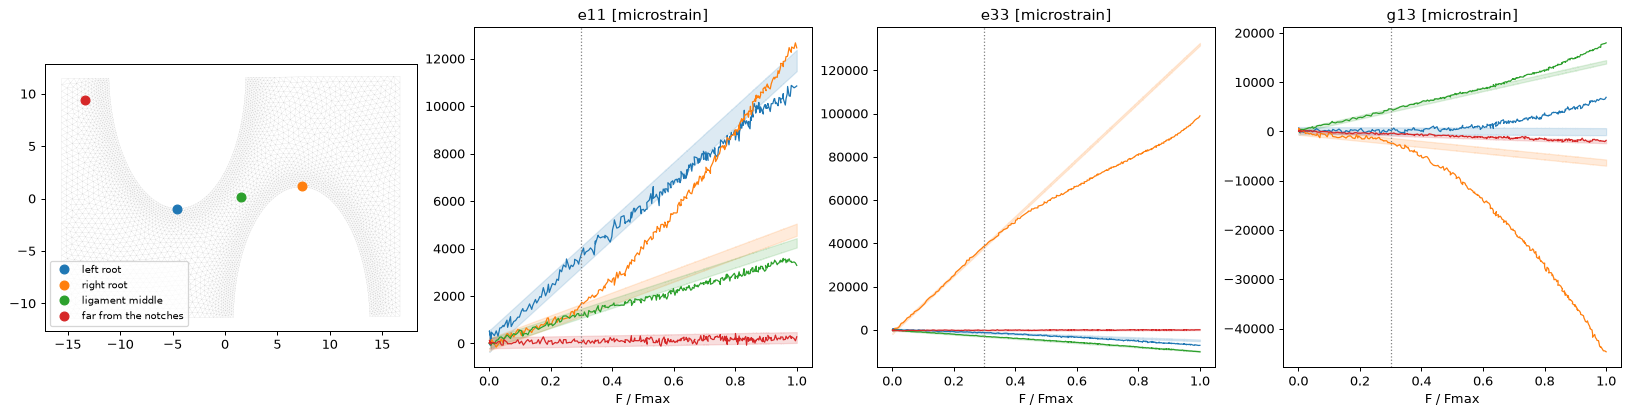

In [9]:
x1, x3 = ds["element_x1"].values, ds["element_x3"].values
d_root = ds["element_root_mm"].values


def nearest(px1, px3):
    return int(np.argmin((x1 - px1) ** 2 + (x3 - px3) ** 2))


mid = roots.mean(axis=0)
chosen = {
    "left root": nearest(*roots[0]),
    "right root": nearest(*roots[1]),
    "ligament middle": nearest(*mid),
    # far from both roots, and at least 2 mm inside the outline
    "far from the notches": int(np.argmax(np.where(ds["element_edge_mm"] > 2, d_root, -1))),
}

LOW = 0.30  # the load window where the response is taken as linear
fit = images[F[images] <= LOW]

fig = plt.figure(figsize=(18, 4.5), constrained_layout=True)
gs = fig.add_gridspec(1, 4, width_ratios=(1.1, 1, 1, 1))
ax0 = fig.add_subplot(gs[0])
ax0.triplot(tri, lw=0.1, color="0.7")
for k, (lab, el) in enumerate(chosen.items()):
    ax0.plot(x1[el], x3[el], "o", color=f"C{k}", ms=7, label=lab)
ax0.set_aspect("equal")
ax0.legend(fontsize=8, loc="lower left")
for c, name in enumerate(data.COMPONENTS):
    ax = fig.add_subplot(gs[c + 1])
    for k, el in enumerate(chosen.values()):
        e = ds["strain"].isel(element=el, component=c) * 1e6
        a, b = np.polyfit(F[fit], e.sel(image=fit).values, 1)
        ax.fill_between(
            F[images],
            (a * F[images] + b) - 3 * sd[el, c] * 1e6,
            (a * F[images] + b) + 3 * sd[el, c] * 1e6,
            color=f"C{k}",
            alpha=0.15,
        )
        ax.plot(F[images], e.sel(image=images).values, color=f"C{k}", lw=1)
    ax.axvline(LOW, color="0.5", ls=":", lw=1)
    ax.set_xlabel("F / Fmax")
    ax.set_title(f"{name} [microstrain]")
plt.show()

## 6. The DIC residual

`residual_rms` says how well the measured motion explains the images in each element, per camera,
in grey levels. About 2.5 is the noise of the images. It rises where the smooth field of the DIC
cannot follow what the images show: a crack opening, the edge of the face, a reflection. It is a
second signal, independent of the strain, worth using.

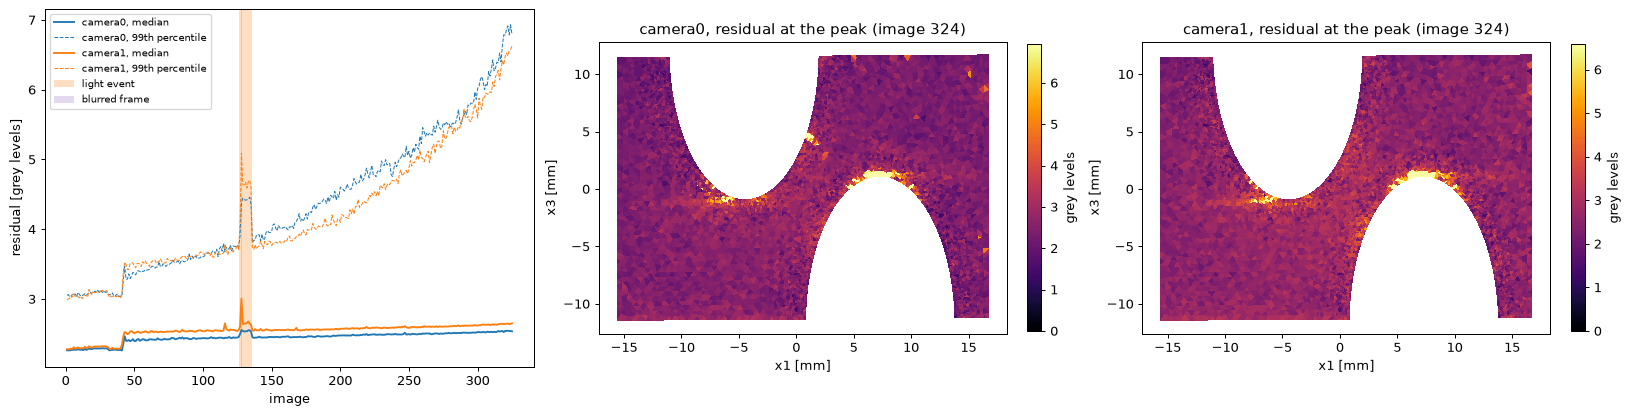

In [10]:
res = ds["residual_rms"].isel(image=slice(1, None))  # image 0 is the reference: no residual
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), constrained_layout=True, width_ratios=(1.2, 1, 1))
for k, cam in enumerate(ds["camera"].values):
    r = res.sel(camera=cam)
    axes[0].plot(r.image, r.median("element"), color=f"C{k}", label=f"{cam}, median")
    axes[0].plot(
        r.image,
        r.quantile(0.99, "element"),
        color=f"C{k}",
        ls="--",
        lw=0.8,
        label=f"{cam}, 99th percentile",
    )
mark(axes[0], light, "tab:orange", "light event")
mark(axes[0], blurred, "tab:purple", "blurred frame")
axes[0].set_xlabel("image")
axes[0].set_ylabel("residual [grey levels]")
axes[0].legend(fontsize=8)
for k, cam in enumerate(ds["camera"].values):
    v = res.sel(camera=cam, image=peak).values
    plotting.element_map(
        ds,
        v,
        ax=axes[k + 1],
        label="grey levels",
        cmap="inferno",
        vmin=0,
        vmax=np.nanpercentile(v, 99),
    )
    axes[k + 1].set_title(f"{cam}, residual at the peak (image {peak})")
plt.show()

`residual_rms` is a plain rms over an element of hundreds of pixels: a crack one or two pixels
wide barely moves it. Two sharper versions come from the residual of every pixel:
`residual_over_floor` (each pixel's fixed part removed, the rms over the element divided by the
noise floor of a moving face: 1 is noise only) and `residual_frac3` (the fraction of the
element's pixels beyond 3 times that floor). Below: both at four load levels, and their median
over zones of the face against the load (elements within 0.5 mm of the outline left out of the
three inner zones). On ARC-00_s0 and ARC-00_m45_s0 the face hardly stood still before loading,
so the floor is higher and the values at rest mean less.

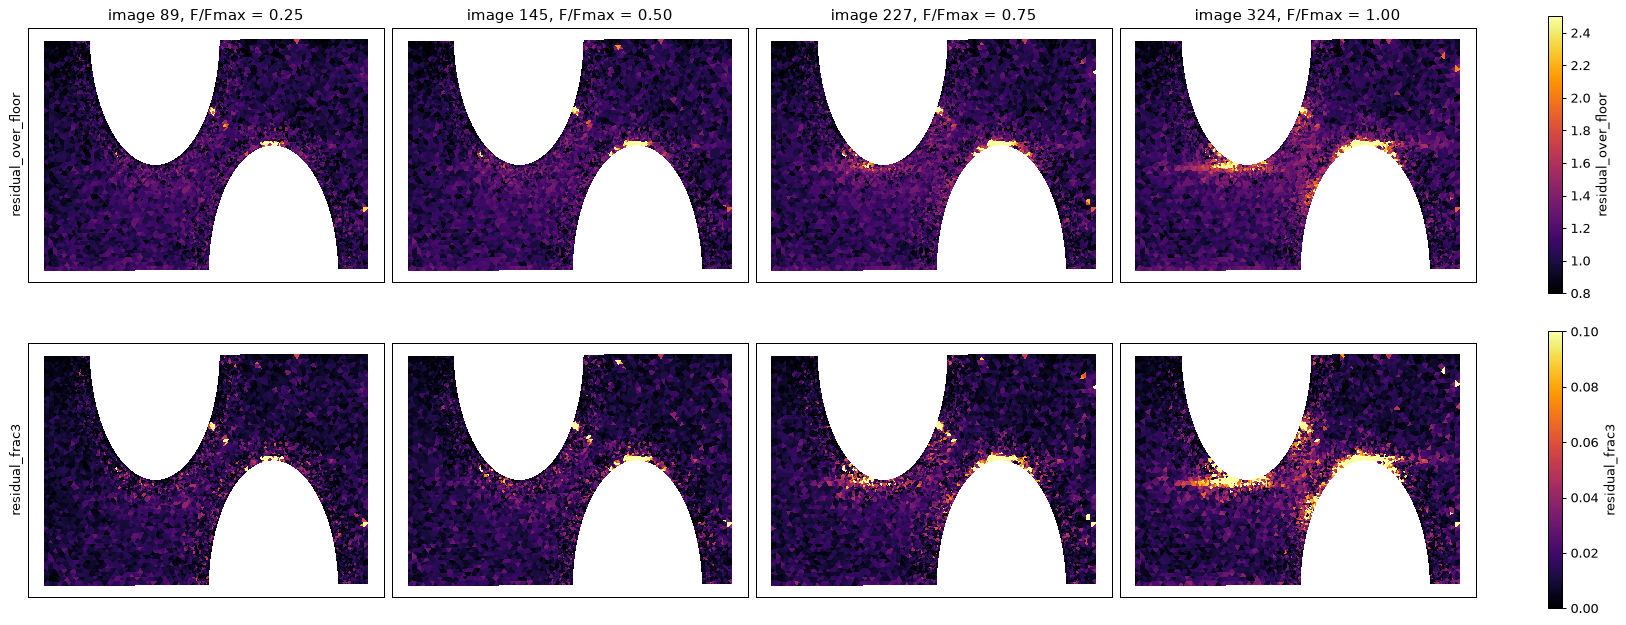

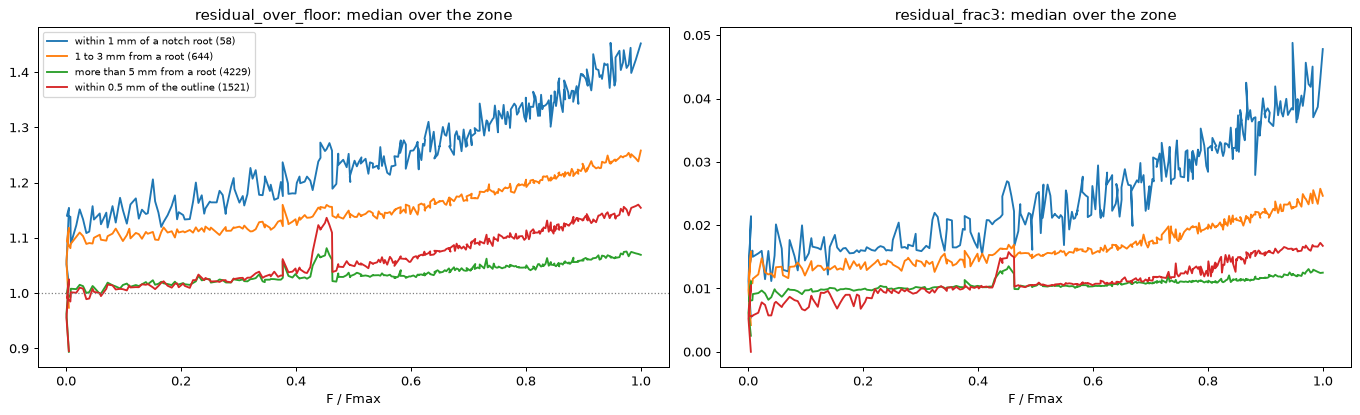

In [11]:
inside = ds["element_edge_mm"].values > 0.5
root_mm = ds["element_root_mm"].values
over, frac3 = ds["residual_over_floor"].values, ds["residual_frac3"].values
pos = {i: j for j, i in enumerate(img)}  # image number -> position
fig, axes = plt.subplots(2, 4, figsize=(18, 7), constrained_layout=True)
for row, (v, name, top) in enumerate(
    [(over, "residual_over_floor", 2.5), (frac3, "residual_frac3", 0.1)]
):
    for j, im in enumerate(picks):
        plotting.element_map(
            ds,
            v[pos[im]],
            ax=axes[row, j],
            colorbar=False,
            cmap="inferno",
            vmin=0 if row else 0.8,
            vmax=top,
        )
        axes[row, j].set_xticks([])
        axes[row, j].set_yticks([])
        axes[row, j].set_xlabel("")
        axes[row, j].set_ylabel(name if j == 0 else "")
        if row == 0:
            axes[row, j].set_title(f"image {im}, F/Fmax = {F[im]:.2f}")
    fig.colorbar(axes[row, -1].collections[0], ax=axes[row, :], shrink=0.9, label=name)
plt.show()

zones = {
    "within 1 mm of a notch root": inside & (root_mm < 1),
    "1 to 3 mm from a root": inside & (root_mm >= 1) & (root_mm < 3),
    "more than 5 mm from a root": inside & (root_mm > 5),
    "within 0.5 mm of the outline": ~inside,
}
keep = np.isin(img, images)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), constrained_layout=True)
for ax, (v, name) in zip(axes, [(over, "residual_over_floor"), (frac3, "residual_frac3")]):
    for z, sel in zones.items():
        ax.plot(F[img[keep]], np.nanmedian(v[keep][:, sel], axis=1), label=f"{z} ({sel.sum()})")
    ax.set_xlabel("F / Fmax")
    ax.set_title(f"{name}: median over the zone")
axes[0].axhline(1, color="0.5", ls=":", lw=1)
axes[0].legend(fontsize=8)
plt.show()

## 7. Displacement

The displacement is given at the nodes, in mm: `u1`, `u3` in the face and `w` out of it, with
the rigid body motion of the coupon removed (it is kept apart in `rigid_motion`, drawn first).
The strain comes from its gradient. The out-of-plane `w` is the least precise of the three (it comes
from the angle between the two cameras), but it shows whether the coupon twists or bends.

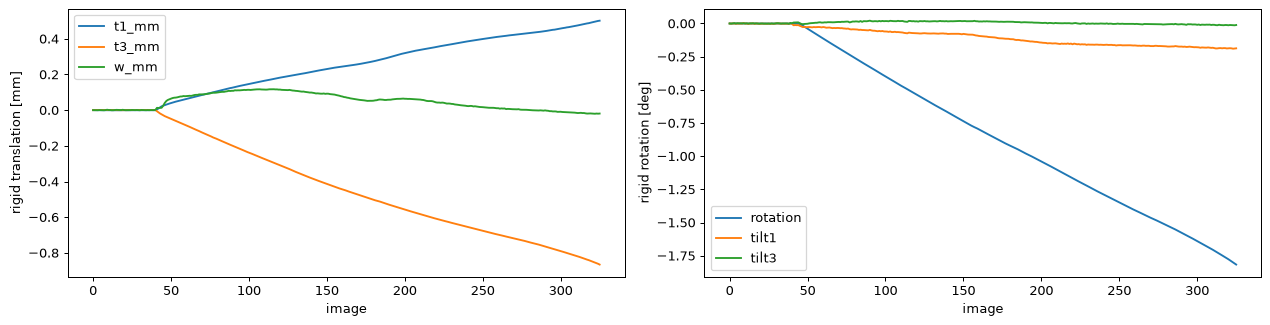

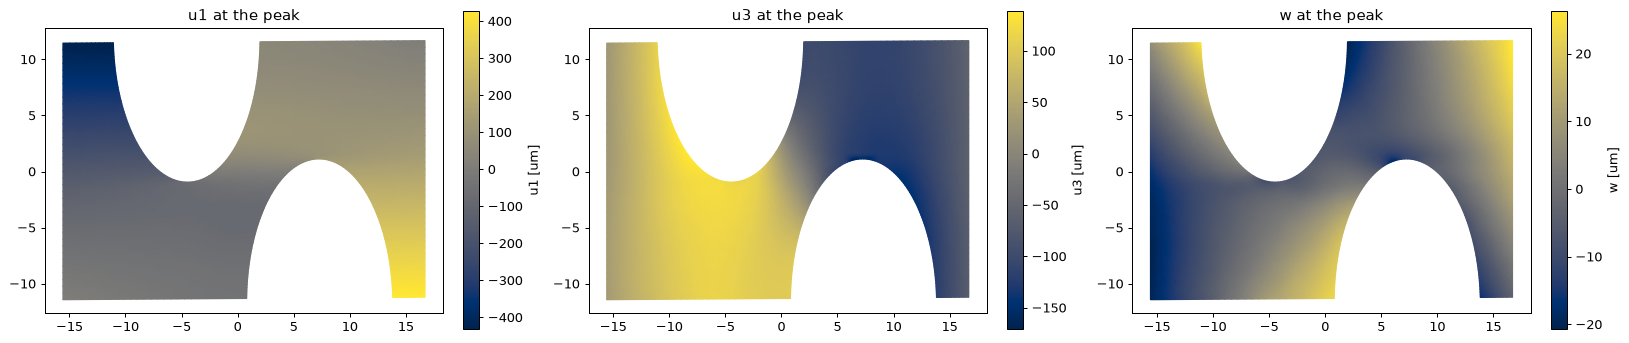

In [12]:
rm = ds["rigid_motion"]
fig, (ax, bx) = plt.subplots(1, 2, figsize=(14, 3.5), constrained_layout=True)
for name in ["t1_mm", "t3_mm", "w_mm"]:
    ax.plot(img, rm.sel(rigid_mode=name), label=name)
ax.set_ylabel("rigid translation [mm]")
for name in ["rotation_rad", "tilt1_rad", "tilt3_rad"]:
    bx.plot(img, np.degrees(rm.sel(rigid_mode=name)), label=name.replace("_rad", ""))
bx.set_ylabel("rigid rotation [deg]")
for a in (ax, bx):
    a.set_xlabel("image")
    a.legend()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), constrained_layout=True)
u = ds["displacement"].sel(image=peak)
for k, dname in enumerate(ds["direction"].values):
    tc = axes[k].tripcolor(
        tri, u.sel(direction=dname).values * 1e3, shading="gouraud", cmap="cividis"
    )
    fig.colorbar(tc, ax=axes[k], shrink=0.8, label=f"{dname} [um]")
    axes[k].set_aspect("equal")
    axes[k].set_title(f"{dname} at the peak")
plt.show()

## 8. The data as arrays

Most methods want plain arrays. Here is the strain over the loading images as one array of shape
`(element, image, component)`, and the same in units of each element's noise, which puts the
three components and every element on one scale.

Two choices made here, both worth revisiting: the static images are left out, and the strain is
divided by the noise at rest.

In [13]:
X = ds["strain"].sel(image=images).values.transpose(1, 0, 2)  # (n_element, n_image, 3)
Z = X / sd[:, None, :]  # in units of the noise at rest
f = F[images]  # (n_image,), the load of each column
print("X", X.shape, f"{X.nbytes / 1e6:.0f} MB;", "f", f.shape)

# the same, long, for pandas: one row per element and image (here only 3 elements)
long = (
    ds["strain"]
    .sel(image=images)
    .isel(element=list(chosen.values()))
    .to_dataframe()
    .strain.unstack("component")
    .reset_index()
)
long["F_over_max"] = F[long["image"].values]
long.head()

X (7377, 283, 3) 25 MB; f (283,)


component,image,element,e11,e33,g13,F_over_max
0,41,0,-0.000084,0.000132,0.000333,0.004767
1,41,1,-0.000004,0.000144,0.000307,0.004767
2,41,2,0.000038,0.000131,0.000005,0.004767
3,41,3,0.000044,-0.000152,0.000210,0.004767
4,42,0,0.000006,-0.000076,0.000286,0.000596


## 9. A first, naive onset

The simplest thing that could work, to have something to beat. For each element and component:

1. fit a straight line of strain against load on the low-load window (up to `LOW`);
2. measure how far the strain then departs from that line, in units of the noise at rest;
3. call *onset* the first image where the largest departure over the three components exceeds
   `K` and stays above it for `HOLD` images in a row.

It is naive on purpose, and you will find out where it fails. A few places to start: is the
response really linear below 30 percent (in this coupon the shear may soften early)? Is the
noise at rest the right scale for a departure that accumulates over many images? Does the result
change much with `K`, `HOLD` and `LOW`? A few elements already "depart" inside the fit window:
what are they?

78% of the elements depart; median at F/Fmax = 0.64


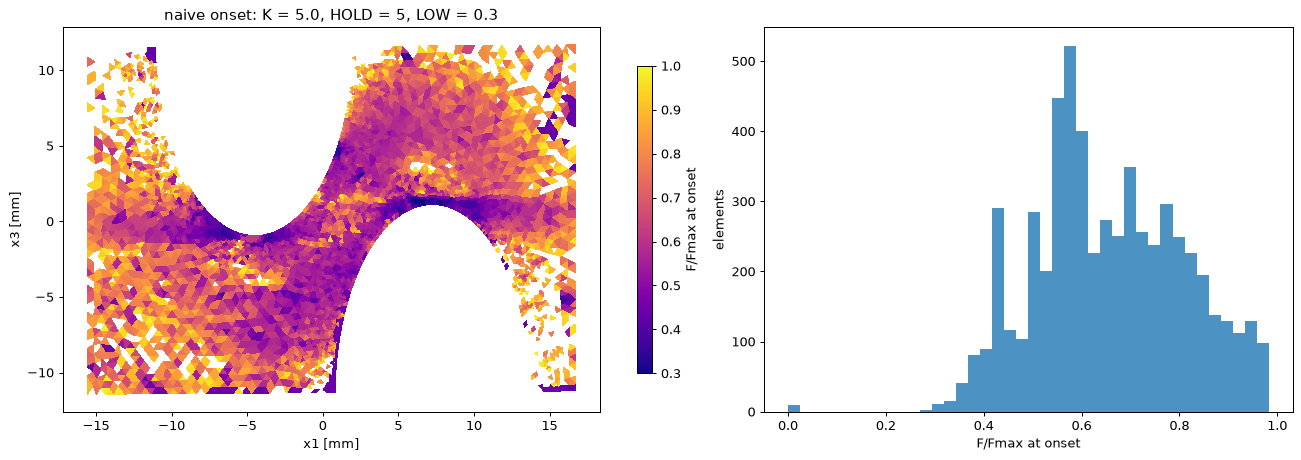

In [14]:
K, HOLD = 5.0, 5


def naive_onset(X, sd, f, low=LOW, k=K, hold=HOLD):
    # departure from a straight line fitted on f <= low, in units of the noise at rest;
    # returns the onset image index (n_element,), -1 if none, and the departure itself
    n_el, n_im, n_c = X.shape
    w = f <= low
    A = np.stack([np.ones(w.sum()), f[w]], axis=1)
    coef, *_ = np.linalg.lstsq(A, X[:, w, :].transpose(1, 0, 2).reshape(w.sum(), -1), rcond=None)
    trend = (np.stack([np.ones(n_im), f], axis=1) @ coef).reshape(n_im, n_el, n_c)
    dev = np.abs(X - trend.transpose(1, 0, 2)) / sd[:, None, :]
    over = (dev.max(axis=2) > k).astype(int)  # (n_element, n_image)
    run = np.cumsum(over, axis=1)  # number of exceedances so far
    run[:, hold:] -= run[:, :-hold].copy()  # exceedances in the last `hold` images
    held = run >= hold
    end = np.where(held.any(axis=1), held.argmax(axis=1), -1)
    start = np.where(end >= 0, end - hold + 1, -1)
    return start, dev


start, dev = naive_onset(X, sd, f)
onset_F = np.where(start >= 0, f[np.clip(start, 0, None)], np.nan)
print(
    f"{np.isfinite(onset_F).mean():.0%} of the elements depart; median at "
    f"F/Fmax = {np.nanmedian(onset_F):.2f}"
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5), constrained_layout=True, width_ratios=(1.4, 1))
plotting.element_map(
    ds, onset_F, ax=axes[0], label="F/Fmax at onset", cmap="plasma", vmin=LOW, vmax=1
)
axes[0].set_title(f"naive onset: K = {K}, HOLD = {HOLD}, LOW = {LOW}")
axes[1].hist(onset_F[np.isfinite(onset_F)], bins=40, color="C0", alpha=0.8)
axes[1].set_xlabel("F/Fmax at onset")
axes[1].set_ylabel("elements")
plt.show()

## 10. Is the noise model right?

Section 9 reads a departure of 5 noise units as if the departure were normal. Two things change
that, and both can be checked where nothing should happen: in the fit window (F <= LOW), where
the line holds by construction.

1. The noise of each element is *estimated*, from K static images only. One component at a time,
   the departure z then follows a Student law with K - 1 degrees of freedom, not a normal one.
   The three components together, through their 3 x 3 noise covariance Sigma, give one distance
   psi = sqrt(eta^T Sigma^-1 eta), which follows Hotelling's T^2 law (chi_3 only if Sigma were
   known exactly).
2. Under load the speckle moves over other pixels of the cameras, which may add noise that the
   static images do not see.

So: choose a false-alarm rate alpha, take the threshold from the T^2 law, and see how many
points of the fit window are beyond it. `onsetml.null` has the pieces.


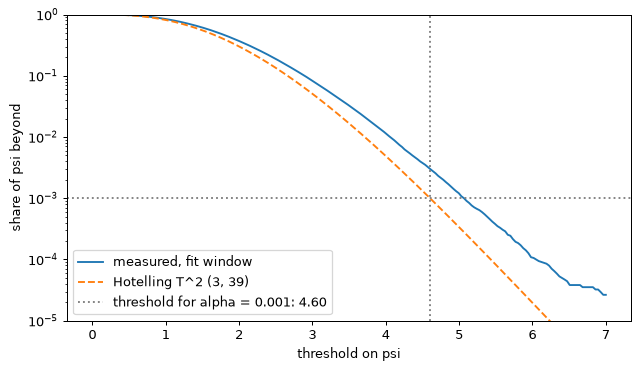

beyond the threshold in the fit window: 0.30% (alpha = 0.10%)
noise under load / noise at rest, median over the elements inside: {'e11': 1.07, 'e33': 1.09, 'g13': 1.13}


In [15]:
from onsetml import null

f_img = F[images]  # (n_image,)
X_ie = ds["strain"].sel(image=images).values  # (n_image, n_element, 3): the layout of onsetml.null
eta = null.departure(f_img, X_ie)  # strain minus its line fitted over F <= LOW
Sigma, K = null.static_covariance(ds)  # (n_element, 3, 3), from K static images
psi = null.psi(eta, Sigma)  # (n_image, n_element)

ALPHA = 1e-3
thr = null.hotelling_threshold(ALPHA, nu=K - 1)
w = f_img <= null.LOW
p_window = psi[w][:, inside].ravel()

x = np.linspace(0, 7, 200)
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.semilogy(x, [(p_window > u).mean() for u in x], label="measured, fit window")
ax.semilogy(x, null.hotelling_sf(x, nu=K - 1), "--", label=f"Hotelling T^2 (3, {K - 1})")
ax.axvline(thr, color="0.5", ls=":", label=f"threshold for alpha = {ALPHA:g}: {thr:.2f}")
ax.axhline(ALPHA, color="0.5", ls=":")
ax.set_ylim(1e-5, 1)
ax.set_xlabel("threshold on psi")
ax.set_ylabel("share of psi beyond")
ax.legend()
plt.show()

ratio = null.sigma_under_load(f_img, X_ie) / sd
print(f"beyond the threshold in the fit window: {(p_window > thr).mean():.2%} (alpha = {ALPHA:.2%})")
print("noise under load / noise at rest, median over the elements inside:",
      {c: round(float(r), 2) for c, r in zip(data.COMPONENTS, np.median(ratio[inside], axis=0))})

Under load the measured tail sits above its law: about three times as many points beyond the
threshold as alpha says, with a noise about 10 percent larger than at rest. A threshold taken
from the law alone gives more false alarms than intended; one calibrated on loaded images, where
the response is known to be elastic, does better. Which noise scale and which law to use is one
of the first questions of the project.

### A first sequential detector: CUSUM

The naive rule looks at one image at a time. CUSUM sums the small departures instead: after the
fit window, each image adds |z| - kappa to a running sum that cannot go below 0, and the alarm
rings when the sum passes h. A slow, steady departure that never crosses 5 sigma on its own is
then caught. kappa = 2 and h = 10 below are a first guess, not a calibration.


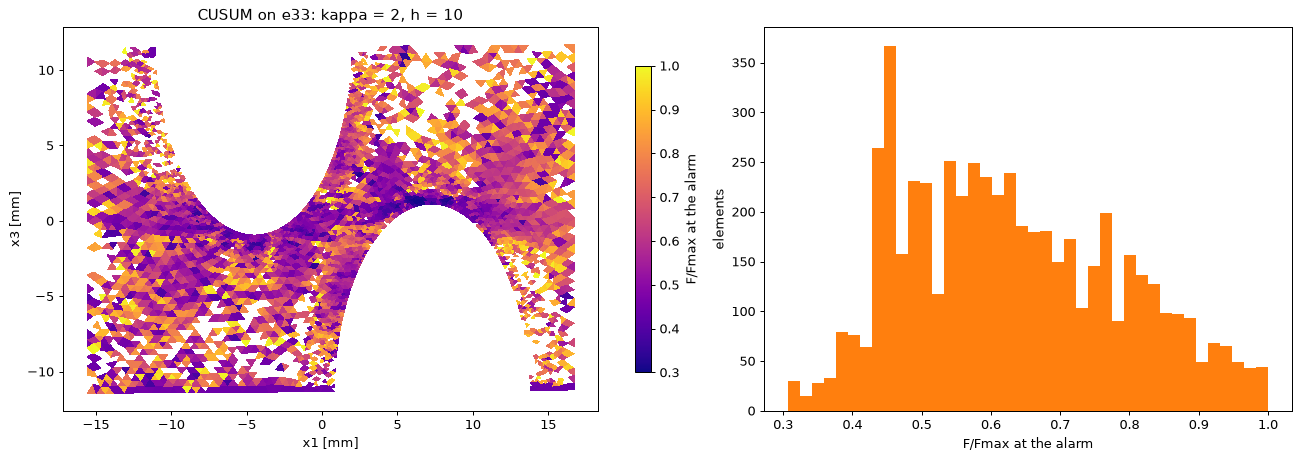

75% of the elements alarm; median at F/Fmax = 0.61


In [16]:
z33 = eta[:, :, 1] / sd[None, :, 1]  # e33 only, in units of the noise at rest
alarm = null.cusum(f_img, z33, kappa=2.0, h=10.0)
cusum_F = np.where(alarm >= 0, f_img[np.clip(alarm, 0, None)], np.nan)

fig, axes = plt.subplots(1, 2, figsize=(16, 5), constrained_layout=True, width_ratios=(1.4, 1))
plotting.element_map(
    ds, cusum_F, ax=axes[0], label="F/Fmax at the alarm", cmap="plasma", vmin=LOW, vmax=1
)
axes[0].set_title("CUSUM on e33: kappa = 2, h = 10")
axes[1].hist(cusum_F[np.isfinite(cusum_F)], bins=40, color="C1")
axes[1].set_xlabel("F/Fmax at the alarm")
axes[1].set_ylabel("elements")
plt.show()
print(f"{np.isfinite(cusum_F).mean():.0%} of the elements alarm; median at "
      f"F/Fmax = {np.nanmedian(cusum_F):.2f}")

The spike of alarms near 0.45 F_max falls on the light dip of section 1 (images 127 to 135,
0.43 to 0.46 F_max): a detector that sums departures also sums artefacts. Masking those images,
or calibrating kappa and h on images with a known answer, is part of the work.


## Where to go from here

The questions of the project, roughly in order:

- **Where and when.** A map of onset load per element that does not depend much on arbitrary
  thresholds, and that you can defend: what makes a departure real rather than noise or light?
  Section 10 gives the null model and a first CUSUM (`onsetml.null`); calibrate them, then try
  the other change-point methods of the proposal (two-segment fits, PELT with `ruptures`) and a
  spatial smoothing of the onset map. About 6000 elements are tested at once: think about the
  false alarms over the whole face, not one element at a time.
- **Kinds of behaviour.** Do the element histories fall into a few families? A first try in the
  kickoff deck (a Gaussian mixture on the shape of each element's departure curves and residual,
  the eight tests together) finds families that differ mainly in the shape of the shear
  departure, in coherent zones of the face. Clustering on the curves of section 8
  (`scikit-learn`, `tslearn`), and whether the families sit in sensible places on the face. On
  these monotonic tests, which stop at the peak, plasticity and diffuse damage both soften
  smoothly: the data alone cannot tell them apart.
- **Second opinion.** Does the DIC residual (section 6) rise where the strain departs?
- **Robustness.** Does an answer survive a change of window, of threshold, and the light dip?

Some practical rules: keep each exploration in its own notebook, dated in its name
(`2026-11-10_onset_cusum.ipynb`). When a result depends on a piece of code, move it into
`src/onsetml/` and give it a test.